# Анализ системы метрик приложения

**Описание проекта**

Procrastinate Pro+ предоставляет пользователям доступ к развлекательному контенту: видео, подкастам и блогам. Пользователи могут выбрать несколько пакетов контента. Пакеты различаются по цене, объёму и содержанию.

*Изменение в продукте*: к началу лета в приложении появился новый вид контента — спортивный. С его помощью менеджеры стремятся расширить аудиторию, добавив в неё пользователей, которые увлекаются спортом и здоровым образом жизни.

К запуску нового контента была скорректирована маркетинговая стратегия привлечения пользователей. Согласно бизнес-модели продукта, привлечение должно окупиться за первые 28 дней (4 недели).

**Проблема**: после запуска нового контента и изменения стратегии интерес к продукту в целом вырос, но выручка начала стагнировать. Нужно разобраться, почему это происходит.

*Что необходимо проанализировать:*
- провести анализ юнит-экономики продукта в динамике за первые 28 дней;
- разобраться в причинах стагнации выручки;
- определить, какие источники привлечения приносят прибыль, а какие не выходят на уровень окупаемости;
- дать рекомендации отделу маркетинга.


### Данные


1. Датасет `ppro_visits.csv` — информация о посещениях приложения пользователями, которые зарегистрировались с 1 апреля 2024 года по 30 ноября 2024 года:
    - `user_id` — уникальный идентификатор пользователя;
    - `region` — страна пользователя;
    - `device` — категория устройства пользователя;
    - `channel` — идентификатор рекламного источника, из которого пришёл пользователь;
    - `session_start` — дата и время начала сессии;
    - `session_end` — дата и время окончания сессии.

2. Датасет `ppro_orders.csv` — информация о покупках:
    - `user_id` — уникальный идентификатор пользователя, который сделал покупку;
    - `event_dt` — дата и время покупки;
    - `revenue` — выручка.

3. Датасет `ppro_costs.csv` — информация о затратах на маркетинг:
    - `dt` — дата
    - `channel` — идентификатор рекламного источника;
    - `costs` — затраты на этот рекламный источник в этот день.
    
### План проекта
- Загрузить и предобработать данные.
- Подготовить данные для когортного анализа.
- Рассчитать и проанализировать метрики вовлечённости в продукт.
- Рассчитать и проанализировать финансовые метрики CAC, LTV и ROI за первые 28 дней с момента привлечения.
- Исследовать метрики в разрезе источника привлечения.
- Рассчитать период окупаемости маркетинговых вложений.
- Сформулировать выводы и рекомендации.


## Загрузка и предобработка данных



Начнем с загрузки библиотек и данных. Будем использовать pandas и библиотеки визуализации данных matplotlib и seaborn. Данные датасетов сохраним в переменных: `df_visits`, `df_orders`, `df_costs`. Далее проведем  предобработку.

In [ ]:
# Импортируем библиотеки
import pandas as pd

# Загружаем библиотеки для визуализации данных
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns

# Дополнительно настроем отображение всех столбцов, строк и ширину вывода
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Отключаем предупреждения
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# Выгружаем данные в датафреймы
df_visits = pd.read_csv('/datasets/ppro_visits.csv')
df_orders = pd.read_csv('/datasets/ppro_orders.csv')
df_costs = pd.read_csv('/datasets/ppro_costs.csv')

Чтобы познакомиться с данными датасетов создадим несколько функций.

In [ ]:
# Функция, которая будет показывать первые строки и информацию о датафрейме
def show_df(df):
    """Функция показывает первые строки датафрейма и информацию о нём.

    Параметры:
    dataframe (pd.DataFrame): датафрейм для анализа
    """
    display(df.head())
    df.info()
    print()


In [ ]:
# Функция для отображения уникальных значений в столбцах датафрейма
def print_count_uniq_values (dataframe, columns):
    """
    Функция для вывода на экран количество уникальные значения в указанных столбцах датафрейма.

    Параметры:
    dataframe (pd.DataFrame): датафрейм для анализа
    columns (list): список столбцов, для которых нужно подсчитать количество уникальных значений
    """
    print('Количество уникальных значений в столбцах датафрейма')
    print('Размер датафрейма:', dataframe.shape[0])
    print()
    for column in columns:
        print(f'Количество уникальных значений в {column}:', dataframe[column].value_counts().count())
    print()


In [ ]:
# Функция для отображения уникальных категориальных значений в столбцах
def print_unique_categorical_values(dataframe, columns):
    """
    Фунция выводит уникальные значения в указанных категориальных столбцах.

    Параметры:
    dataframe (pd.DataFrame): датафрейм для анализа
    columns (list): список столбцов для отображения уникальных значений
    """
    for column in columns:
        print(f'{column}: {dataframe[column].unique()}')
    print()

In [ ]:
def show_duplicates(dataframe):
    """
    Функция показывает дублирующиеся строки, если они есть.

    Параметры:
    dataframe (pd.DataFrame): датафрейм для анализа

    Возвращает:
    pd.DataFrame или None: DataFrame с дубликатами или None, если дубликатов нет
    """
    duplicates = dataframe[dataframe.duplicated(keep=False)]

    if duplicates.empty:
        print('Дубликатов нет\n')
        return None  # Возвращаем None вместо пустого DataFrame
    else:
        print(f'Найдено дубликатов: {len(duplicates)} строк\n')
        return duplicates

In [ ]:
# Знакомимся с данными датасета ppro_visits.csv
show_df(df_visits)

,user_id,region,device,channel,session_start,session_end
0,631105188566,India,desktop,MediaTornado,2024-04-01 03:48:00,2024-04-01 04:19:00
1,892885906464,India,tv,RocketSuperAds,2024-04-01 00:47:00,2024-04-01 01:14:00
2,517003690029,India,mobile,MediaTornado,2024-04-01 17:31:00,2024-04-01 17:53:00
3,185156659289,India,mobile,MediaTornado,2024-04-01 14:36:00,2024-04-01 14:51:00
4,409503040345,India,mobile,RocketSuperAds,2024-04-01 08:25:00,2024-04-01 08:45:00


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 161865 entries, 0 to 161864
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   user_id        161865 non-null  int64 
 1   region         161865 non-null  object
 2   device         161865 non-null  object
 3   channel        161865 non-null  object
 4   session_start  161865 non-null  object
 5   session_end    161865 non-null  object
dtypes: int64(1), object(5)
memory usage: 7.4+ MB



In [ ]:
# Выводим уникальные категориальные значения
print_unique_categorical_values(df_visits, ['region', 'device', 'channel'])

# Выведем количество уникальных пользователей датафрейма
print_count_uniq_values(df_visits, ['user_id'])

# Проверим датафрейм на наличие явных дубликатов
show_duplicates(df_visits)

region: ['India']
device: ['desktop' 'tv' 'mobile']
channel: ['MediaTornado' 'RocketSuperAds' 'FaceBoom' 'TipTop']

Количество уникальных значений в столбцах датафрейма
Размер датафрейма: 161865

Количество уникальных значений в user_id: 74856

Дубликатов нет



In [ ]:
# Опеределим временные диапазоны столбцов с датой
start_min, start_max = df_visits['session_start'].min(), df_visits['session_start'].max()
end_min, end_max = df_visits['session_end'].min(), df_visits['session_end'].max()

print(f'session_start: {start_min} - {start_max}')
print(f'session_end:   {end_min} - {end_max}')

session_start: 2024-04-01 00:07:00 - 2024-11-30 23:59:00
session_end:   2024-04-01 00:22:00 - 2024-12-01 01:40:00


Датасет `ppro_visits.csv` содержит 161865 строк и 6 столбцов, в которых представлена информация о посещениях приложения пользователями. Названия столбцов имеют вид snake case, что является стандартом для работы с табличными данными. Значения в столбцах соответствуют своему описанию.

Для дальнейшей работы создадим столбец `dt_session`,  в котором будет храниться дата сессии, округлённая до дня.

In [ ]:
# Создадим новый столбец dt_session, в котором будет храниться дату сессии
df_visits['dt_session'] =  pd.to_datetime(df_visits['session_start']).dt.normalize()


# Для проверки выведем тип столбца
df_visits['dt_session'].dtype

dtype('<M8[ns]')

In [ ]:
# Знакомимся с данными датасета ppro_orders.csv
show_df(df_orders)

,user_id,event_dt,revenue
0,771951256319,2024-04-01 05:56:26,2.99
1,829942381059,2024-04-01 14:55:02,2.99
2,727879856738,2024-04-01 22:15:09,14.99
3,481270888930,2024-04-01 06:05:14,2.99
4,844695029762,2024-04-01 01:19:52,2.99


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33893 entries, 0 to 33892
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   user_id   33893 non-null  int64  
 1   event_dt  33893 non-null  object 
 2   revenue   33893 non-null  float64
dtypes: float64(1), int64(1), object(1)
memory usage: 794.5+ KB



In [ ]:

# Выведем количество уникальных платящих пользователей датафрейма
print_count_uniq_values(df_orders, ['user_id'])

# Проверим датафрейм на наличие явных дубликатов
show_duplicates(df_orders)

Количество уникальных значений в столбцах датафрейма
Размер датафрейма: 33893

Количество уникальных значений в user_id: 6889

Дубликатов нет



In [ ]:
# Опеределим временные диапазоны столбцов с датой
start_min, start_max = df_orders['event_dt'].min(), df_orders['event_dt'].max()

print(f'event_dt: {start_min} - {start_max}')

event_dt: 2024-04-01 00:53:40 - 2024-11-30 23:55:50


Датасет `ppro_visits.csv` содержит 33893 строк и 3 столбца, в которых представлена информация о покупках.
 **Названия столбцов** имеют вид snake case, значения соответствуют описанию. **Тип данных**: дату и время покупки преобразуем к типу datetime64.


In [ ]:
# Преобразуем event_dt к типу datetime64
df_orders['event_dt'] =  pd.to_datetime(df_orders['event_dt']).dt.normalize()


In [ ]:
# Знакомимся с данными датасета ppro_costs.csv
show_df(df_costs)

,dt,channel,costs
0,2024-04-01,FaceBoom,124.938874
1,2024-04-02,FaceBoom,88.147779
2,2024-04-03,FaceBoom,120.779457
3,2024-04-04,FaceBoom,98.981253
4,2024-04-05,FaceBoom,109.044760


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 976 entries, 0 to 975
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   dt       976 non-null    object 
 1   channel  976 non-null    object 
 2   costs    976 non-null    float64
dtypes: float64(1), object(2)
memory usage: 23.0+ KB



In [ ]:
# Выведем количество уникальных дат
print_count_uniq_values(df_costs, ['dt'])

# Проверим датафрейм на наличие явных дубликатов
show_duplicates(df_costs)

Количество уникальных значений в столбцах датафрейма
Размер датафрейма: 976

Количество уникальных значений в dt: 244

Дубликатов нет



In [ ]:
# Опеределим временные диапазоны столбцов с датой
start_min, start_max = df_costs['dt'].min(), df_costs['dt'].max()

print(f'dt: {start_min} - {start_max}')

dt: 2024-04-01 - 2024-11-30


У датасета `ppro_costs.csv` 976 строк и 3 столбца, в которых содержится информация о затратах на маркетинг.
 **Названия столбцов** имеют вид snake case, значения соответствуют описанию. **Тип данных**: дату преобразуем к типу datetime64.

In [ ]:
# Преобразуем дату к типу datetime64

df_costs ['dt'] =  pd.to_datetime(df_costs ['dt'])

In [ ]:
# Создаем копии датасетов до преобразования для возможности проверить сделанные изменения после предобработки
df_costs_temp = df_costs.copy()
df_orders_temp = df_orders.copy()
df_visits_temp = df_visits.copy()

**Промежуточные выводы**

На первом этапе работы были загружены и проанализированы три датасета, которые содержат взаимосвязанные данные о пользовательской активности (161865 записей), покупках (33893) и маркетинговых затратах (976).

Все данные относятся к одному региону - `India`. Пользователи используют три типа устройств: `desktop`, `tv` и `mobile`. Всего четыре канала привлечения: `MediaTornado`, `RocketSuperAds`, `FaceBoom` и `TipTop`.
Все три датасета содержат данные по одному временному периоду (8 месяцев, апрель-ноябрь 2024). Приложение за период использовали 74856 уникальных пользователя, из них 6889 совершали покупки (значит доля платящих пользователей около 10%). Названия столбцов оформленны корректно и отражают хранимые сведения. Отсутствуют дубликаты, пропущенные значения и явные аномалии.

Проведена предобработка: даты преобразованы в формат `datetime`. Создано новое поле `dt_session` в данных о посещениях. Данные готовы для когортного анализа.

## Подготовка данных к когортному анализу

Подготовка данных для когортного анализа окупаемости привлечения пользователей за первые 28 дней. Для этого:

- Посчитаем для каждого пользователя дату первой сессии (first_dt) и определим канал привлечения (first_channel). Рассчитаем стоимость привлечения каждого пользователя (cac).

- Сохраним результаты в отдельную таблицу profiles.

- Добавим к данным о событиях и покупках информацию о первом источнике привлечения и дате привлечения пользователя.

- Рассчитаем дневной лайфтайм для каждого события или покупки в виде целого числа.

В дальнейшем когортном анализе будем использовать информацию о первом источнике привлечения пользователя.

In [ ]:
# Подготовим данные для когортного анализа. Для каждого пользователя найдем:
# - дату первой сессии (дату привлечения пользователя),
# - канал привлечения (первый канал привлечения),
# - стоимость привлечения пользователя (затраты на маркетинг, CAC)

# Сгруппируем данные по пользователю, чтобы получить первые два показателя.
profiles = df_visits.groupby('user_id').agg(
    first_dt=('dt_session', 'min'),
    first_channel=('channel', 'first')).reset_index()


# Выведем на экран таблицу profiles после объединения
show_df(profiles)


,user_id,first_dt,first_channel
0,26034876,2024-05-29,FaceBoom
1,69890364,2024-06-28,RocketSuperAds
2,75610104,2024-06-09,FaceBoom
3,76692397,2024-10-21,FaceBoom
4,80224421,2024-06-21,FaceBoom


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74856 entries, 0 to 74855
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   user_id        74856 non-null  int64         
 1   first_dt       74856 non-null  datetime64[ns]
 2   first_channel  74856 non-null  object        
dtypes: datetime64[ns](1), int64(1), object(1)
memory usage: 1.7+ MB



In [ ]:
# Рассчитаем количество уникальных пользователей, привлеченных по дням и каналам
daily_channel_users = profiles.groupby(['first_dt', 'first_channel'])['user_id'].nunique().reset_index(name='user_count')

# Объединяем таблицу daily_channel_users и с таблицей маркетинговых затрат для расчета САС
df_costs = pd.merge(df_costs, daily_channel_users, how='left',
                    right_on=['first_dt', 'first_channel'],
                    left_on=['dt', 'channel'])

# Рассчитываем САС
df_costs['cac'] = df_costs['costs'] / df_costs['user_count']

# Добавляем к таблице profiles рассчитанное CAC
profiles = pd.merge(profiles, df_costs[['first_dt','first_channel','cac']],
                    on=['first_dt','first_channel'], how='left')

# Выведем таблицу profiles с информацие
show_df(profiles)

,user_id,first_dt,first_channel,cac
0,26034876,2024-05-29,FaceBoom,0.953250
1,69890364,2024-06-28,RocketSuperAds,0.604917
2,75610104,2024-06-09,FaceBoom,1.196159
3,76692397,2024-10-21,FaceBoom,1.147967
4,80224421,2024-06-21,FaceBoom,1.208981


<class 'pandas.core.frame.DataFrame'>
Int64Index: 74856 entries, 0 to 74855
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   user_id        74856 non-null  int64         
 1   first_dt       74856 non-null  datetime64[ns]
 2   first_channel  74856 non-null  object        
 3   cac            74856 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 2.9+ MB



Объединим созданную таблицу profiles с таблицами событий и покупок, чтобы добавить к информацию о первом источнике привлечения и дате привлечения пользователя.

In [ ]:
# Объединяем таблицы profiles и df_visits
df_visits = pd.merge(df_visits,
                     profiles[['user_id', 'first_dt', 'first_channel']],
                     on='user_id',
                     how='left')
# Объединяем таблицы profiles и df_orders
df_orders = pd.merge(df_orders,
                     profiles[['user_id', 'first_dt', 'first_channel']],
                     on='user_id',
                     how='left')

Рассчитаем дневной лайфтайм для каждого события и покупки.

In [ ]:
# Рассчитаем дневной лайфтайм для каждого события.
df_visits['n_period'] = (df_visits['dt_session'] - df_visits['first_dt']).dt.days

# Рассчитаем дневной лайфтайм для каждой покупки.
df_orders['n_period'] = (df_orders['event_dt'] - df_orders['first_dt']).dt.days


In [ ]:
# Выведем на экран таблицы после объединения
show_df(df_visits)
show_df(df_orders)

# Проверим, не изменился ли размер таблиц, после добавления новых столбцов
print()
print(df_visits.shape[0] == df_visits_temp.shape[0])
print(df_orders.shape[0] == df_orders_temp.shape[0])

,user_id,region,device,channel,session_start,session_end,dt_session,first_dt,first_channel,n_period
0,631105188566,India,desktop,MediaTornado,2024-04-01 03:48:00,2024-04-01 04:19:00,2024-04-01,2024-04-01,MediaTornado,0
1,892885906464,India,tv,RocketSuperAds,2024-04-01 00:47:00,2024-04-01 01:14:00,2024-04-01,2024-04-01,RocketSuperAds,0
2,517003690029,India,mobile,MediaTornado,2024-04-01 17:31:00,2024-04-01 17:53:00,2024-04-01,2024-04-01,MediaTornado,0
3,185156659289,India,mobile,MediaTornado,2024-04-01 14:36:00,2024-04-01 14:51:00,2024-04-01,2024-04-01,MediaTornado,0
4,409503040345,India,mobile,RocketSuperAds,2024-04-01 08:25:00,2024-04-01 08:45:00,2024-04-01,2024-04-01,RocketSuperAds,0


<class 'pandas.core.frame.DataFrame'>
Int64Index: 161865 entries, 0 to 161864
Data columns (total 10 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   user_id        161865 non-null  int64         
 1   region         161865 non-null  object        
 2   device         161865 non-null  object        
 3   channel        161865 non-null  object        
 4   session_start  161865 non-null  object        
 5   session_end    161865 non-null  object        
 6   dt_session     161865 non-null  datetime64[ns]
 7   first_dt       161865 non-null  datetime64[ns]
 8   first_channel  161865 non-null  object        
 9   n_period       161865 non-null  int64         
dtypes: datetime64[ns](2), int64(2), object(6)
memory usage: 13.6+ MB



,user_id,event_dt,revenue,first_dt,first_channel,n_period
0,771951256319,2024-04-01,2.99,2024-04-01,FaceBoom,0
1,829942381059,2024-04-01,2.99,2024-04-01,FaceBoom,0
2,727879856738,2024-04-01,14.99,2024-04-01,FaceBoom,0
3,481270888930,2024-04-01,2.99,2024-04-01,TipTop,0
4,844695029762,2024-04-01,2.99,2024-04-01,FaceBoom,0


<class 'pandas.core.frame.DataFrame'>
Int64Index: 33893 entries, 0 to 33892
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   user_id        33893 non-null  int64         
 1   event_dt       33893 non-null  datetime64[ns]
 2   revenue        33893 non-null  float64       
 3   first_dt       33893 non-null  datetime64[ns]
 4   first_channel  33893 non-null  object        
 5   n_period       33893 non-null  int64         
dtypes: datetime64[ns](2), float64(1), int64(2), object(1)
memory usage: 1.8+ MB


True
True


**Промежуточные выводы**

Создана таблица profiles с информацией о дате первого визита, первом источнике привлечения и стоимости привлечения (CAC). Для каждого пользователя определены когортные признаки. Эти данные добавлены в основные таблицы событий и покупок. Рассчитан лайфтайм в днях для каждого события и покупки как разница между датой события и датой привлечения.

## Анализ месячной динамики основных метрик продукта

В этом разделе:
1) Изучим динамику активности пользователей и их вовлечённости в продукт. Рассчитайте по всем данным значения DAU, MAU и Stickiness и визуализируем их. Будем считать активными всех пользователей, которые взаимодействовали с приложением.

2) В разрезе каждого месяца привлечения новых пользователей рассчитаем:
- среднюю стоимость привлечения пользователя (CAC)
- значение LTV и ROI с учётом покупок, совершённых за 28 дней с момента привлечения.

При расчёте LTV и ROI будем учитывать всех привлечённых пользователей когорты.

Сделаем визуализацию метрик и подведем промежуточные вывод.

<p style="font-size:20px"><strong>DAU, MAU и Stickiness</strong></p>


Расчитаем и визуализируем метрики DAU и MAU. На основе их построим метрику Stickiness.

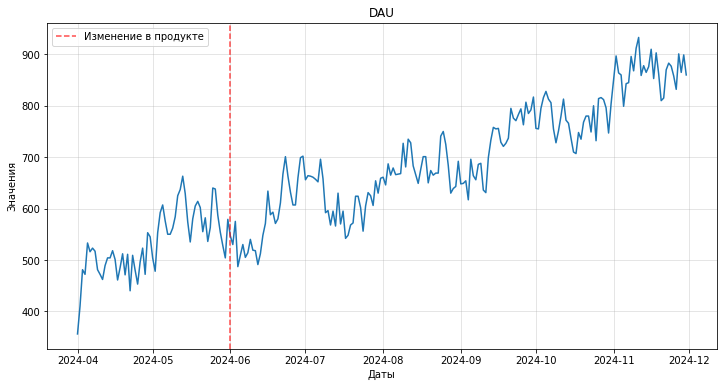

In [ ]:
# Сгруппируем уникальных пользователей по дням (dt_session), чтобы рассчитать DAU
dau = df_visits.groupby('dt_session')['user_id'].nunique().reset_index(name = 'dau')

# Строим график в matplotlib
plt.subplots(figsize=(12,6))
plt.plot(dau['dt_session'], dau['dau'])

# Добавим красную линию (июнь 2024 года), чтобы показать момент появления нового вида контента в продукте
# и изменения маркетинговой стратегии привлечения пользователей
plt.axvline(x = pd.Timestamp('2024-06-01'), color='red', linestyle='--', alpha=0.7, label='Изменение в продукте')

# Оформляем график
plt.title('DAU')
plt.xlabel('Даты')
plt.ylabel('Значения')
plt.legend()
plt.grid(alpha=0.4)
plt.show()

На графике видно, что DAU растет на протяжении всего периода. Заметны волнообразные колебания, шаг которых равен примерно одному месяцу. Из-за колебаний сложно сказать, повлияло ли появления нового вида контента в продукте и изменения маркетинговой стратегии привлечения пользователей на увеличение ежедневной аудитории приложения. Рост DAU наблюдался и до начала лета.
<br> Далее расчитаем MAU.

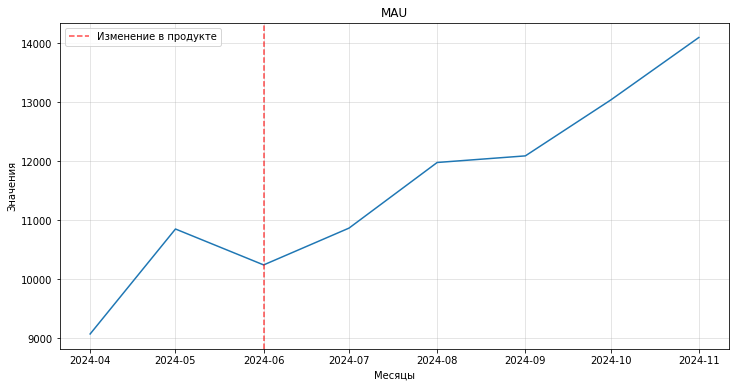

In [ ]:
# Создаем в таблице df_visits столбец с месецем активности
df_visits['month'] = df_visits['dt_session'].dt.to_period('M').dt.to_timestamp()

# Группируем уникальных пользователей по месяцам, чтобы рассчитать MAU
mau = df_visits.groupby('month')['user_id'].nunique().reset_index(name='mau')

# Строим график в matplotlib
plt.subplots(figsize=(12,6))
plt.plot(mau['month'], mau['mau'])

# Покажем красной линией момент летнего изменеия в продукте
plt.axvline(x = pd.Timestamp('2024-06-01'), color='red', linestyle='--', alpha=0.7, label='Изменение в продукте')

# Оформляем график
plt.title('MAU')
plt.xlabel('Месяцы')
plt.ylabel('Значения')
plt.legend()
plt.grid(alpha=0.4)
plt.show()

Так же, как и DAU, показатель MAU улучшался в течение всего периода: аудитория приложения растёт. Единственное исключение — июнь 2024 года, но после этого метрика продолжила рост. Отметим, что возобновление роста MAU совпадает по времени с внедрением изменений в продукт и маркетинговые стратегии, что может отражать интерес к новому контенту.

Перейдём к метрике вовлечённости (Stickiness).

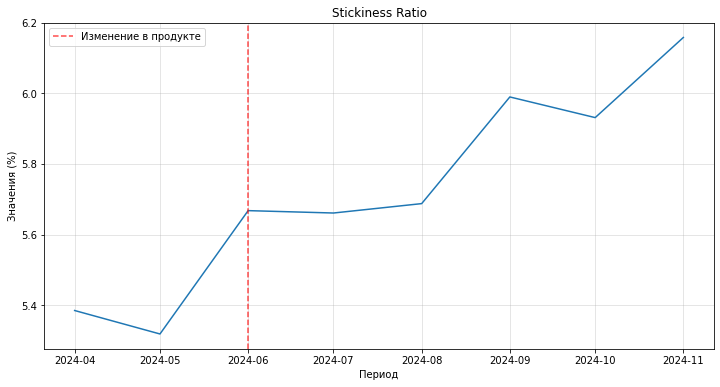

In [ ]:

# Создаем столбец month в таблице dau с округлением даты сессии до начала месяца
dau['month'] = dau['dt_session'].dt.to_period('M').dt.to_timestamp()

# Группируем среднее количество пользователей по месяцам и  считаем средний DAU по месяцам
dau_monthly_average = dau.groupby('month')['dau'].mean().reset_index(name='dau_avg')

# Объединяем средний DAU по месяцам с MAU по месяцам, чтобы рассчитать Stickiness
stickiness_table = pd.merge(dau_monthly_average, mau, on='month', how='inner')

# Рассчитываем метрику Stickiness как отношение среднего DAU к MAU в процентах
stickiness_table['stickiness'] = (stickiness_table['dau_avg'] / stickiness_table['mau']) * 100

# Строим график в matplotlib
plt.subplots(figsize=(12,6))
plt.plot(stickiness_table['month'], stickiness_table['stickiness'])

# Покажем красной линией июнь 2024 года - момент появления нового вида контента в продукте
# и изменения маркетинговой стратегии привлечения пользователей
plt.axvline(x = pd.Timestamp('2024-06-01'), color='red', linestyle='--', alpha=0.7, label='Изменение в продукте')

# Оформляем график
plt.title('Stickiness Ratio')
plt.xlabel('Период')
plt.ylabel('Значения (%)')
plt.legend()
plt.grid(alpha=0.4)
plt.show()


Наблюдается постепенный рост метрики Stickiness (залипания) с 5.3% в апреле до 6.1% в ноябре, что говорит об улучшении ежедневной вовлечённости пользователей относительно месячной аудитории. Особенно заметен скачок в июне (5.3% в мае, 5.6% в июне). Скачок совпадает с запуском нового контента и может указывать на его положительное влияние на регулярность использования приложения. Однако стоит отметить, что метрика ежедневно активных пользователей увеличивается медленно.

<p style="font-size:20px"><strong>CAC, LTV и ROI по месяцам</strong></p>


Расчитаем среднюю стоимость привлечения пользователя (CAC) в разрезе каждого месяца.

In [ ]:
# Создаем столбец с месяцем привлечения пользователя в продукт
profiles['first_month'] = profiles['first_dt'].dt.to_period('M').dt.to_timestamp()

# Рассчитаем CAC стоимость привлечения платящего пользователя в разрезе месяца
cac_monthly = profiles.groupby('first_month', as_index=False)['cac'].mean()

# Выводим результат на экран
display(cac_monthly)

,first_month,cac
0,2024-04-01,0.734706
1,2024-05-01,0.748572
2,2024-06-01,0.973978
3,2024-07-01,1.054344
4,2024-08-01,1.155601
5,2024-09-01,1.178301
6,2024-10-01,1.323047
7,2024-11-01,1.320148


Визуализируем динамику САС по месяцам на линейном графике.

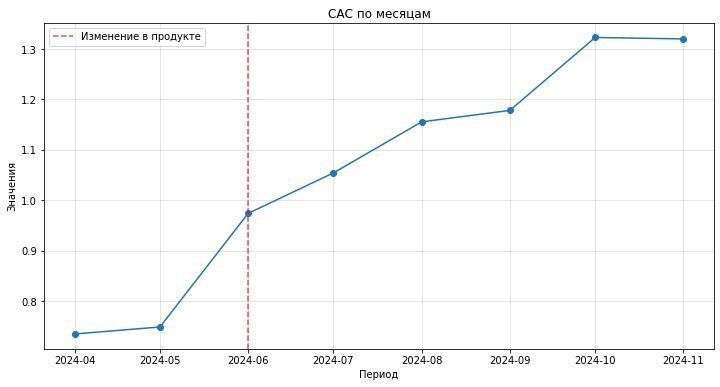

In [ ]:
# Строим график в matplotlib
plt.subplots(figsize=(12,6))
plt.plot(cac_monthly['first_month'], cac_monthly['cac'], marker='o')

# Покажем красной линией июнь 2024 года - момент появления нового вида контента в продукте
# и изменения маркетинговой стратегии привлечения пользователей
plt.axvline(x=pd.Timestamp('2024-06-01'), color='red', linestyle='--', alpha=0.7, label='Изменение в продукте')

# Оформляем график
plt.title('САС по месяцам')
plt.xlabel('Период')
plt.ylabel('Значения')
plt.legend()
plt.grid(alpha=0.4)
plt.show()

CAC увеличивался с июня - то есть месяца появления нового контента в продукте и изменения маркетинговой стратегии. Только в октябре-ноябре затраты на маркетинг в расчете на одного привлеченного пользователя остались на одном уровне. До изменений в продуете САС был на уровне 0.72-0.74, а в октябре-ноябре 1.31.<br>

Рассчитаем значение LTV и ROI с учётом покупок, совершённых за 28 дней с момента привлечения.

In [ ]:
# В таблице df_visits с сессиями пользователей формируем когорты по месяцам привлечения
df_visits['first_month'] = df_visits['first_dt'].dt.to_period('M').dt.to_timestamp()

# Оставляем сессии, совершенные в первые 28 дней жизни пользователя
# Считаем количество уникальных пользователей по когортам (месяцам привлечения)
user_count = (
    df_visits[df_visits['n_period'] < 28]
    .groupby('first_month')['user_id']
    .nunique()
    .reset_index(name='count_users')
)

# В таблице с заказми формируем когорты по месяцам привлечения
df_orders['first_month'] = df_orders['first_dt'].dt.to_period('M').dt.to_timestamp()

# Оставляем покупки, совершенные в первые 28 дней
# Считаем суммарную выручку по когортам (месяцам привлечения)
month_revenue = (
    df_orders[df_orders['n_period'] < 28]
    .groupby('first_month', as_index=False)['revenue']
    .sum()
)

# Объединяем данные по пользователям и суммарной  выручке для расчета LTV
ltv_monthly = pd.merge(user_count, month_revenue, on='first_month', how='left')

# Рассчитываем LTV - средняя выручка на одного пользователя за первые  28 дней
ltv_monthly['ltv'] = ltv_monthly['revenue'] / ltv_monthly['count_users']

# Формируем итоговую таблицу метрик: объединяем LTV и CAC
cac_ltv_roi_monthly = pd.merge(ltv_monthly, cac_monthly, on='first_month', how='left')

# Рассчитываем ROI по формуле (LTV - CAC) / CAC * 100
cac_ltv_roi_monthly['roi'] = (cac_ltv_roi_monthly['ltv'] - cac_ltv_roi_monthly['cac']) / cac_ltv_roi_monthly['cac'] * 100

# Выводим результат
display(cac_ltv_roi_monthly)


,first_month,count_users,revenue,ltv,cac,roi
0,2024-04-01,9069,7425.63,0.818793,0.734706,11.444870
1,2024-05-01,9789,8141.76,0.831725,0.748572,11.108209
2,2024-06-01,8719,7447.84,0.854208,0.973978,-12.297015
3,2024-07-01,8742,9991.41,1.142920,1.054344,8.401051
4,2024-08-01,9518,10367.05,1.089205,1.155601,-5.745639
5,2024-09-01,9198,10085.88,1.096530,1.178301,-6.939783
6,2024-10-01,9520,11449.71,1.202701,1.323047,-9.096121
7,2024-11-01,10301,8893.98,0.863409,1.320148,-34.597554


Визуализируем динамику LTV в сравнеии с CAC за 28 дней для разных когорт (месяцев).

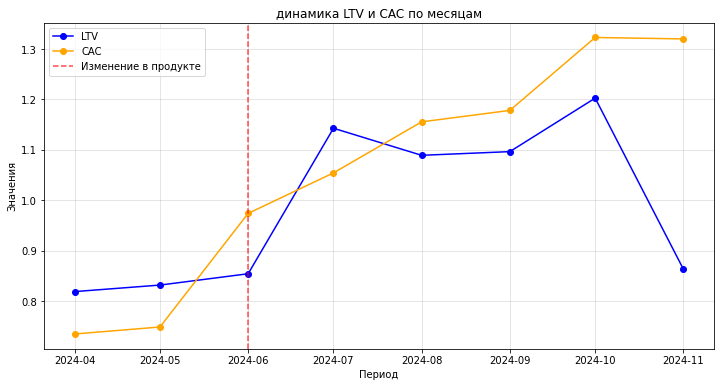

In [ ]:
# Строим график в matplotlib
plt.subplots(figsize=(12,6))
plt.plot(cac_ltv_roi_monthly['first_month'], cac_ltv_roi_monthly['ltv'], marker='o', color='blue', label = 'LTV')
plt.plot(cac_ltv_roi_monthly['first_month'], cac_ltv_roi_monthly['cac'], marker='o', color='orange', label = 'CAC')
# Покажем красной линией июнь 2024 года - момент изменений в продукте
# и изменения маркетинговой стратегии привлечения пользователей
plt.axvline(x=pd.Timestamp('2024-06-01'), color='red', linestyle='--', alpha=0.7, label='Изменение в продукте')

# Оформляем график
plt.title('динамика LTV и CAC по месяцам')
plt.xlabel('Период')
plt.ylabel('Значения')
plt.legend()
plt.grid(alpha=0.4)
plt.show()

На графике видно, что после внедрения изменений в продукт в июне затраты на привлечение пользователей (CAC) стали систематически превышать выручку, которую эти пользователи приносят в первые 28 дней (LTV). Только в июля LTV кратковременно превысил CAC. С августа по октябрь кривая LTV повторяет траекторию СAC, что говорит о том, что при увеличении затрат на маркетинг, выручка тоже увеличивается, однако не превышает расходы. Низкое значение LTV в ноябре связано с тем, что данные представлены до 30 ноября 2024 года, что не позволяет учесть выручку от всех пользователей за полные 28 дней.

Вызуализируем значение ROI.

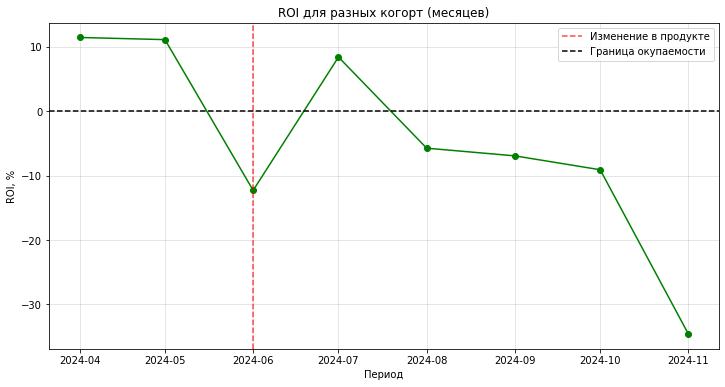

In [ ]:
# Строим график в matplotlib
plt.subplots(figsize=(12,6))
plt.plot(cac_ltv_roi_monthly['first_month'], cac_ltv_roi_monthly['roi'], marker='o', color='green')

# Покажем красной линией июнь 2024 года - момент изменений в продукте
# и изменения маркетинговой стратегии привлечения пользователей
plt.axvline(x=pd.Timestamp('2024-06-01'), color='red', linestyle='--', alpha=0.7, label='Изменение в продукте')

# Добавляем горизонтальную линию — границу окупаемости
plt.axhline(y=0, color='black', linestyle='--', label='Граница окупаемости')


# Оформляем график
plt.title('ROI для разных когорт (месяцев)')
plt.xlabel('Период')
plt.ylabel('ROI, %')
plt.legend()
plt.grid(alpha=0.4)
plt.show()

До июня метрика ROI составляла 11%, но в июне опускается до -12%. Далее только в июле метрика пересекает уровень покупаемости, достигая значения 8%. В период с августа по октябрь метрика медленно снижается от -5.7% до -9%.  Опять же ROI в ноябре не рассматриваем в анализе, поскольку данные собраны до 30 ноября 2024 года и не все пользователи когорты прожили в продукте 28 дней.



**Промежуточный вывод** <br>

За исключением июня, метрики **DAU** и **MAU** демонстрируют улучшения после внедрения изменений в продукт: аудитория приложения растёт. Рост метрик совпадает по времени с внедрением изменений в продукт. Это может говорить об успешности маркетинговых стратегий и интерес к новому контенту. Однако для уверенных выводов необходимо больше  данных: в распоряжении есть только два месяца до изменений (апрель–май) и пять месяцев после (июль–ноябрь). Чтобы корректно оценить динамику DAU и MAU в контексте летних изменений, нужен более длинный исторический период (например, с начала года).


Метрика **вовлечённости (Stickiness)** демонстрирует медленную положительную динамику, увеличившись за период с апреля по ноябрь. Значительный рост в июне совпадает с запуском нового контента, что может говорить о его положительное влияние на пользовательскую активность.

С появлением нового спортивного контента и изменения маркетиновой стратегии в началае лета 2024 года новая аудитория не окупается за 28-и дневный период жизни пользователей: **стоимость привлечения (CAC)** значительно выросла и превышает **выручку за первые 28 дней (LTV)**. Только в июле **ROI** пересекает уровень покупаемости, в остальные месяцы с июня по октябрь - нет.

## Анализ метрик в разрезе источника привлечения

В этом разделе:

1) Определяем популярность и активность по источникам привлечения <br>
Рассчитаем общее количество привлечённых пользователей для каждого канала, визуализируем дневную динамику притока новых пользователей, а также построим графики DAU, MAU и Stickiness в разрезе источников привлечения.

2) Анализируем эффективность каналов за первые 28 дней <br>
В разрезе каждого источника привлечения проведём когортный анализ с недельной детализацией. Рассчитаем и визуализируем:

- скользящее удержание на 14-й день жизни (период 14–28 дней);

- конверсию в покупку;

- недельную динамику маркетинговых затрат;

- динамику среднего CAC, LTV и ROI.

Сравниваем и характеризуем рекламные каналы<br>
На основе рассчитанных метрик дадим общую характеристику каждому каналу, выявим источники, не достигшие окупаемости за 28 дней, и предложим гипотезы о причинах их низкой эффективности.


<p style="font-size:20px"><strong>Активность пользователей по каналам</strong></p>


Посчитаем общее число привлечённых пользователей для каждого источника.


In [ ]:
# Рассчитаем общее число привлеченных пользователей по каждому каналу
channel_users = df_visits.groupby('first_channel', as_index=False)['user_id'].nunique()

# Выведем число привлечнных пользователей по источникам, отсортировав их по убыванию
display(channel_users.sort_values(by='user_id', ascending=False))

,first_channel,user_id
0,FaceBoom,28401
3,TipTop,18118
2,RocketSuperAds,14257
1,MediaTornado,14080


Распределение привлеченных пользователей по каналам неравномерное: канал FaceBoom привлекает более чем в 1.5 раза больше пользователей, чем TipTop, и почти вдвое больше, чем RocketSuperAds и MediaTornado.

Визуализируем динамику набора новых пользователей по дням в каждом источнике.

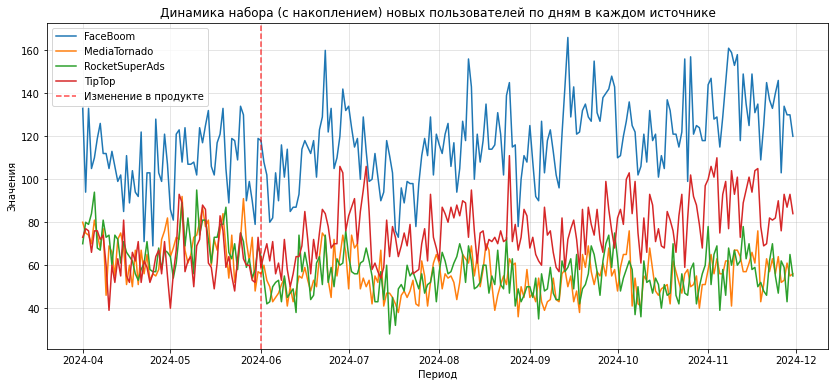

In [ ]:

# Группируем данные по дате привлечения и источнику, считаем уникальных пользователей за каждый день
user_channel_daily = df_visits.groupby(['first_dt', 'first_channel'], as_index=False)['user_id'].nunique()

# Создадим список с каналами
first_channel = user_channel_daily['first_channel'].unique()

# Строим график в matplotlib
plt.subplots(figsize=(14,6))

# Строим графики для каждого канала
for channel in first_channel:
    df_plot = user_channel_daily[user_channel_daily['first_channel'] == channel]
    plt.plot(df_plot['first_dt'], df_plot['user_id'], label = channel)

# Покажем красной линией момент летнего изменеия в продукте
plt.axvline(x = pd.Timestamp('2024-06-01'), color='red', linestyle='--', alpha=0.7, label='Изменение в продукте')

# Оформляем график
plt.title('Динамика набора (с накоплением) новых пользователей по дням в каждом источнике')
plt.xlabel('Период')
plt.ylabel('Значения')
plt.legend()
plt.grid(alpha=0.4)
plt.show()

На графике видно, что по каналам FaceBoom и TipTop число привлеченных пользователей растет с колебаниями на протяжении всего периода, а для RocketSuperAds и MediaTornado, наоборот, снижается в июне (месяц, когда произошло изменение в продукте) и стабилизируется примерно на одном уровне. FaceBoom на протяжении всего периода остается основным источником привлечения аудитории.

<p style="font-size:20px"><strong>DAU, MAU и Stickiness по каналам привлечения</strong></p>


Рассчитаем и визуализируем динамику DAU, MAU и Stickiness по источникам привлечения.

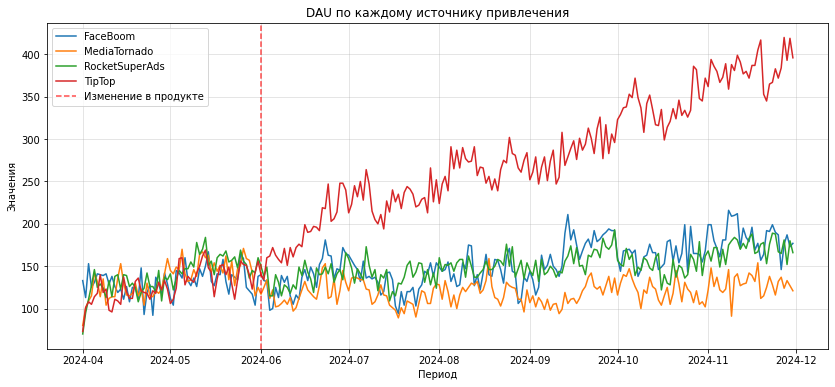

In [ ]:
# Сгруппируем уникальных пользователей по дням активности и источникам
dau_channel = df_visits.groupby(['dt_session', 'first_channel'])['user_id'].nunique().reset_index(name='dau')

# Строим график в matplotlib
plt.subplots(figsize=(14,6))

# Строим графики для каждого канала
for channel in first_channel:
    df_plot = dau_channel[dau_channel['first_channel'] == channel]
    plt.plot(df_plot['dt_session'], df_plot['dau'], label = channel)

# Покажем красной линией момент летнего изменеия в продукте
plt.axvline(x = pd.Timestamp('2024-06-01'), color='red', linestyle='--', alpha=0.7, label='Изменение в продукте')


# Оформляем график
plt.title('DAU по каждому источнику привлечения')
plt.xlabel('Период')
plt.ylabel('Значения')
plt.legend()
plt.grid(alpha=0.4)
plt.show()



Анализ DAU выявил разрыв в активности пользователей между каналами.

Начиная с июня 2024 года, **TipTop** демонстрирует опережающий рост DAU, постепенно увеличивая отрыв от остальных источников: с апреля по ноябрь рост ежедневной аудитории примерно с 100 до 400.

Примечательно, что несмотря на то, что **FaceBoom** занимает первое место по общему числу привлеченных пользователей, по уровню DAU он сопоставим с каналами **RocketSuperAds** и **MediaTornado** и существенно уступает **TipTop**.

Динамика DAU **FaceBoom** и **RocketSuperAds** колеблется на уровне 100-200, а у **MediaTornado** - 100-150 на протяжении всего времени.

Для дальнейшего анализа рассчитаем метрики MAU и прилипание (Stickiness).

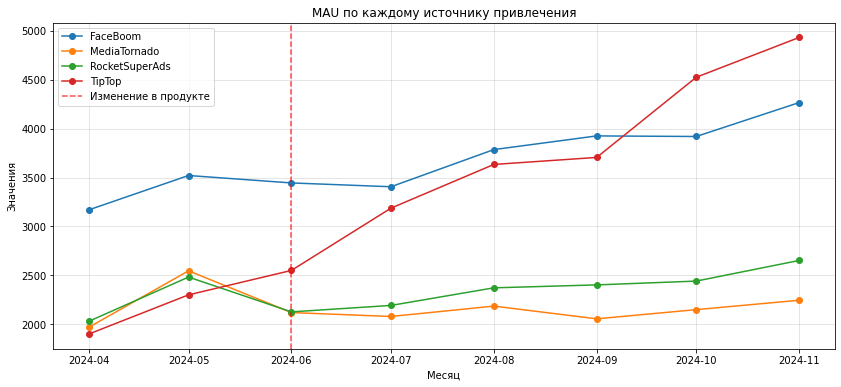

In [ ]:
# Группируем уникальных пользователей по месяцам активности и источникам
mau_channel = df_visits.groupby(['month', 'first_channel'])['user_id'].nunique().reset_index(name='mau')

# Строим график в matplotlib
plt.subplots(figsize=(14,6))

# Строим графики для каждого канала
for channel in first_channel:
    df_plot = mau_channel[mau_channel['first_channel'] == channel]
    plt.plot(df_plot['month'], df_plot['mau'], marker='o', label = channel)

# Покажем красной линией момент летнего изменеия в продукте
plt.axvline(x = pd.Timestamp('2024-06-01'), color='red', linestyle='--', alpha=0.7, label='Изменение в продукте')

# Оформляем график
plt.title('MAU по каждому источнику привлечения')
plt.xlabel('Месяц')
plt.ylabel('Значения')
plt.legend()
plt.grid(alpha=0.4)
plt.show()

На данном грифике также наблюдаем разную динамику MAU для разных источников.

Месячная аудитория **TipTop** растёт быстрее остальных источников на протяжении всего периода: с апреля по ноябрь увеличение в более чем 2 раза (от около 1900 до 5000).

Для **FaceBoom** метрика также улудшалась, но примерно на треть: от 3200 до 4250.

MAU у **RocketSuperAds** и **MediaTornado** находится примерно на одном уровне с небольшими колебаниями.

Стоит обратить внимание, что месячная аудитория всех источников росла и до начала лета (= изменений в продукте).

Расчёт метрики Stickiness позволит сравнит ежедневное использовании продукта пользователями, которые пришли из разных источников привлечения.

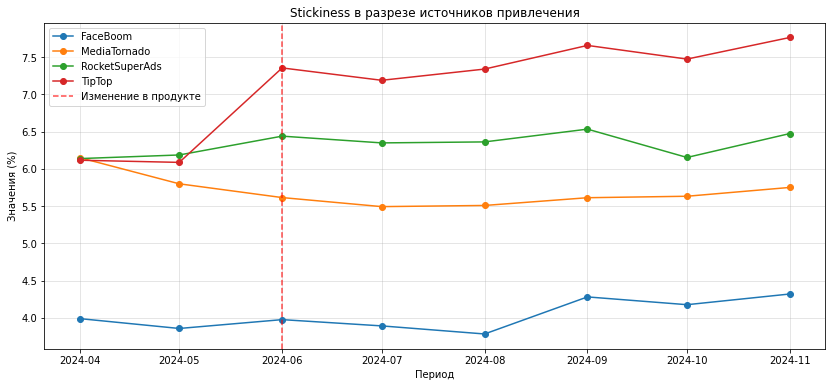

In [ ]:
# Создаем столбец с округлением даты сессии до начала месяца для группировки по месяцам
dau_channel['month'] = dau_channel['dt_session'].dt.to_period('M').dt.to_timestamp()

# Группируем среднее количество пользователей по месяцам, чтобы рассчитать средний DAU по месяцам
dau_avg_channel = dau_channel.groupby(['month', 'first_channel'])['dau'].mean().reset_index(name='dau_avg')

# Объединяем средний DAU по месяцам с MAU по месяцам, чтобы рассчитать Stickiness
stickiness_channel = pd.merge(
    dau_avg_channel,
    mau_channel,
    on=['month', 'first_channel'],
    how='inner',
    suffixes=('_dau', '_mau')
)

# Рассчитываем метрику Stickiness как отношение среднего DAU к MAU в процентах
stickiness_channel['stickiness'] = (stickiness_channel['dau_avg'] / stickiness_channel['mau']) * 100

# Строим график в matplotlib
plt.subplots(figsize=(14,6))

# Строим графики для каждого канала
for channel in first_channel:
    df_plot = stickiness_channel[stickiness_channel['first_channel'] == channel]
    plt.plot(df_plot['month'], df_plot['stickiness'], marker='o', label = channel)


# Покажем красной линией момент летнего изменеия в продукте
plt.axvline(x = pd.Timestamp('2024-06-01'), color='red', linestyle='--', alpha=0.7, label='Изменение в продукте')

# Оформляем график
plt.title('Stickiness в разрезе источников привлечения')
plt.xlabel('Период')
plt.ylabel('Значения (%)')
plt.legend()
plt.grid(alpha=0.4)
plt.show()


Самый высокий показатель по липкости (Stickiness) у пользователей, пришедших из **TipTop**: они активнее остальных взаимодействуют с приложением. Метрика канала в апреле была около 6.1%, значительно выросла в июне - 7.3% и сохранила общий тренд роста до ноября, достигрун 7.7%. Этот рост можно связать с летним изменением в продукте и маркетинге.

Метрика для пользователей из **RocketSuperAds** оказалась более стабильно без заметных влияний летних изменений: колебания за всё время были в пределах 6.1-6.5%.

Stickiness для пользователей, которые пригли из канала **MediaTornado** снизилась с 6.1% до 5.5%, затем стала медленно расти достинув 5.8%.

Метрика Stickiness пользователей из **FaceBoom**, который привлекает значительную долю пользователей в продукт (больше трети от общего количества), оказалась ниже остальных: ее показатель колеблется в районе 4-4.3%.



**Промежуточный вывод**:

**FaceBoom** является основным источником привлечения пользователей на протяжении всего рассматриваемого периода (с апреля по ноябрь 2024): больше 1/3 пришли в приложении именно из него. Однако пришедшая аудитория слабо вовлечена в продукт: MAU высокий относительно DAU, Stickiness низкий. Получается через этот источник приходит значительная часть нецелевой аудитории. Стоит отметить, что вышесказанное характерно для этого источника и до летних изменений.

**TipTop** занимает вторую позицию по общему числу привлеченных пользователей. С июня канал стал быстро наращивать как число привлекаемых пользователей, так и DAU и MAU. При этом также произошел рост метрики Stickiness. Этот канал с лета становится основным по всем показателям и через него приходит более вовлечённая и активная аудитория.

**RocketSuperAds** и **MediaTornado** привлекают меньше пользователей и у них схожи показатели DAU и MAU. Показатель "липкости" занимает средную позицию.



<p style="font-size:20px"><strong>Удержание в разрезе источника</strong></p>


Теперь перейдем к изучению динамики изменения метрик на 28-й день в разрезе источника. Необходимо провести анализ с выделением недельных когорт по дате привлечения. Рассчитать и визуализировать:

- Скользящее удержание на 14-й день с момента привлечения (за период с 14-го по 28-й день).
- Конверсию в покупку.

In [ ]:
# Формируем когорты: выбираем данные о пользователях, каналах и датах привлечения
week_cohort = df_visits[['user_id', 'first_channel', 'first_dt']]

# Создаем столбец с неделей первой активности пользователя (когорта)
week_cohort['first_week'] = week_cohort['first_dt'].dt.to_period('W').dt.to_timestamp()

# Cчитаем общее число  привлеченных пользователей в недельную когорту
week_cohort_count = week_cohort.groupby(['first_week', 'first_channel'])['user_id'].nunique().reset_index(name='users_count')

# Фильтруем сессии, произошедшие в период с 14-го по 28-й день жизни пользователя
week_cohort_period_14_28 = df_visits[df_visits['n_period'].between(13, 27)]

# Создаем столбец с неделей первой активности пользователя
week_cohort_period_14_28['first_week'] = week_cohort_period_14_28['first_dt'].dt.to_period('W').dt.to_timestamp()

# Считаем количество пользователей, которые были активны в период 14-28 дней
week_cohort_period_14_28 = week_cohort_period_14_28.groupby(['first_week', 'first_channel'])['user_id'].nunique().reset_index(name='users_retained')

# Объединяем таблицы с количеством пользователей и количеством удержанных пользователей ща период
retention_table = pd.merge(week_cohort_count, week_cohort_period_14_28, on=['first_week', 'first_channel'], how='left')

# Считаем скользящее удержание
retention_table['retention'] = retention_table['users_retained'] / retention_table['users_count'] * 100

# Выводим полученную таблицу на экран
show_df(retention_table)




,first_week,first_channel,users_count,users_retained,retention
0,2024-04-01,FaceBoom,820,10.0,1.219512
1,2024-04-01,MediaTornado,522,56.0,10.727969
2,2024-04-01,RocketSuperAds,542,70.0,12.915129
3,2024-04-01,TipTop,516,68.0,13.178295
4,2024-04-08,FaceBoom,749,11.0,1.468625


<class 'pandas.core.frame.DataFrame'>
Int64Index: 140 entries, 0 to 139
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   first_week      140 non-null    datetime64[ns]
 1   first_channel   140 non-null    object        
 2   users_count     140 non-null    int64         
 3   users_retained  132 non-null    float64       
 4   retention       132 non-null    float64       
dtypes: datetime64[ns](1), float64(2), int64(1), object(1)
memory usage: 6.6+ KB



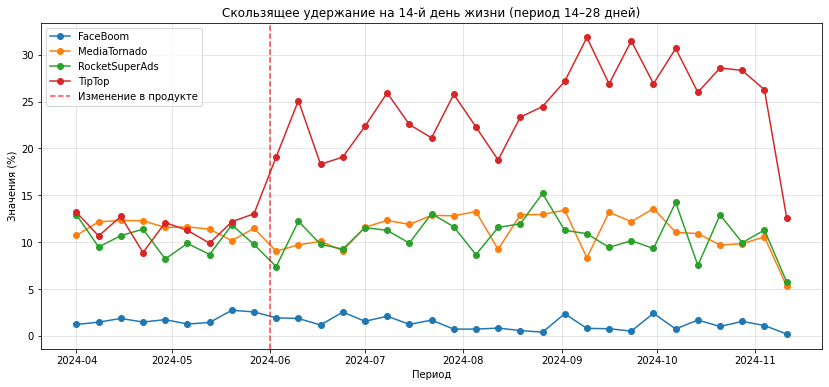

In [ ]:
# Строим график в matplotlib
plt.subplots(figsize=(14,6))

# Строим графики для каждого канала
for channel in first_channel:
    df_plot = retention_table[retention_table['first_channel'] == channel]
    plt.plot(df_plot['first_week'], df_plot['retention'], marker='o', label = channel)


# Покажем красной линией момент летнего изменеия в продукте
plt.axvline(x = pd.Timestamp('2024-06-01'), color='red', linestyle='--', alpha=0.7, label='Изменение в продукте')

# Оформляем график
plt.title('Cкользящее удержание на 14-й день жизни (период 14–28 дней)')
plt.xlabel('Период')
plt.ylabel('Значения (%)')
plt.legend()
plt.grid(alpha=0.4)
plt.show()

**TipTop** демонстрирует стабильно высокое удержание (18-32%), начиная с июня, значительно превосходя другие каналы. Пиковые значения достигают 31-32% в сентябре-октябре. Отметим, что только этот канал показывает рост с начала лета, что еще раз говорит о положительном эффекте от нового контента и маркетинговых изменений.

**FaceBoom** показывает критически низкие показатели (0.2-2.7%) на протяжении всего времени, что свидетельствует о проблемах с качеством трафика или onboarding пользователей.

**MediaTornado** и **RocketSuperAds** находятся на среднем уровне (8-13%) с небольшими колебаниями.

Важное замечание: данные собраны до 30 ноября 2024 года. Для последних двух ноябрьских когорт период удержания (14–28 день) ещё  не завершился, поэтому значения удержания отсутствуют.

<p style="font-size:20px"><strong>Конверсия в покупку в разрезе канала</strong></p>


Перейдем к расчёту и визуализации конверсии в покупку. У нас нет в данных информации о типе событий в приложении (например, установка приложения, добавления в корзину, оформление заказа, покупку). Будем считать конверсию в покупку с применением окна атрибуции - 28 дней. Посчитаем отношние числа пользователей когорты, совершивших покупку

In [ ]:
# Определяем окно атрибуции покупок - 28 дней с момента привлечения (с 0 по 27)
attribution_window = 27

# Создаем таблицу с покупками для расчета конверсии
orders_count = df_orders

# Создаем столбец с когортой пользователя (первая неделя)
orders_count['first_week'] =  orders_count['first_dt'].dt.to_period('W').dt.to_timestamp()

# Фильтруем покупки, совершенные в течение 28 дней с момента привлечения
orders_count_period_28 = orders_count[orders_count['n_period'].between(0, attribution_window)]


# Группируем данные по неделе и каналу привлечения, считаем уникальных платящих пользователей
# Переименовываем столбец для ясности: количество уникальных платящих пользователей за первые 28 дней
orders_count_weekly = orders_count_period_28.groupby(
    ['first_week', 'first_channel'])['user_id'].nunique().reset_index(name='count_payers_28_days')


# Объединяем датафреймы по неделе и источнику привлечения
conversion_table = pd.merge(
    week_cohort_count,
    orders_count_weekly,
    on=['first_week', 'first_channel'],
    how='left'
)

# Рассчитываем конверсию в покупку как отношение платящих пользователей ко всем привлеченным
conversion_table['conversion_rate'] = 100 * (conversion_table['count_payers_28_days'] / conversion_table['users_count'])

# Сортируем данные по неделе и источнику для удобства анализа
conversion_table = conversion_table.sort_values(['first_week', 'first_channel'])

#Выводим таблицу
show_df(conversion_table)

,first_week,first_channel,users_count,count_payers_28_days,conversion_rate
0,2024-04-01,FaceBoom,820,93,11.341463
1,2024-04-01,MediaTornado,522,24,4.597701
2,2024-04-01,RocketSuperAds,542,45,8.302583
3,2024-04-01,TipTop,516,48,9.302326
4,2024-04-08,FaceBoom,749,78,10.413885


<class 'pandas.core.frame.DataFrame'>
Int64Index: 140 entries, 0 to 139
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   first_week            140 non-null    datetime64[ns]
 1   first_channel         140 non-null    object        
 2   users_count           140 non-null    int64         
 3   count_payers_28_days  140 non-null    int64         
 4   conversion_rate       140 non-null    float64       
dtypes: datetime64[ns](1), float64(1), int64(2), object(1)
memory usage: 6.6+ KB



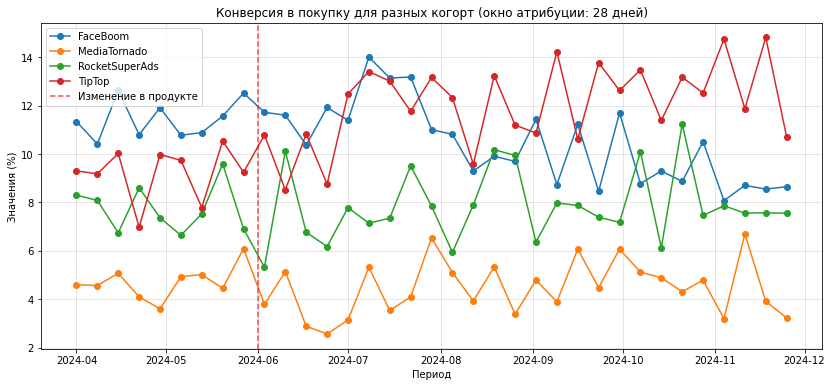

In [ ]:

# Строим график в matplotlib
plt.subplots(figsize=(14,6))

# Строим графики для каждого канала
for channel in first_channel:
    df_plot = conversion_table[conversion_table['first_channel'] == channel]
    plt.plot(df_plot['first_week'], df_plot['conversion_rate'], marker='o', label = channel)

# Покажем красной линией момент летнего изменеия в продукте
plt.axvline(x = pd.Timestamp('2024-06-01'), color='red', linestyle='--', alpha=0.7, label='Изменение в продукте')


# Оформляем график
plt.title(f'Конверсия в покупку для разных когорт (окно атрибуции: {attribution_window + 1} дней)')
plt.xlabel('Период')
plt.ylabel('Значения (%)')
plt.legend()
plt.grid(alpha=0.4)
plt.show()

Общий уровень конверсии низкий: в среднем 8-12% пользователей совершают покупку в первые 28 дней.

**FaceBoom** демонстрирует стабильно высокую конверсию (8-14%), что контрастирует с его низкими показателями удержания. Скорее всего, пользователи из этого источника быстро монетизируются, но не возвращаются. **TipTop** после июньских изменений показывает рост конверсии с 9-10% до 12-14%, становясь с августа лидером по монетизации. **MediaTornado** имеет наиболее низкую и стабильную конверсию (3-6%), что вместе с хорошим удержанием говорит о привлечении лояльной, но не платежеспособной аудитории. **RocketSuperAds** занимает промежуточное положение со стабильно конверсией 6-10%.


<p style="font-size:20px"><strong>Затраты на маркетинг, CAC, LTV и ROI в разрезе канала</strong></p>



Перейдем к заключительному заданию в этой части проекта. Рассчитаем: недельную динамику затрат на маркетинг по каждому источнику привлечения, динамику среднего CAC, значений LTV и ROI.

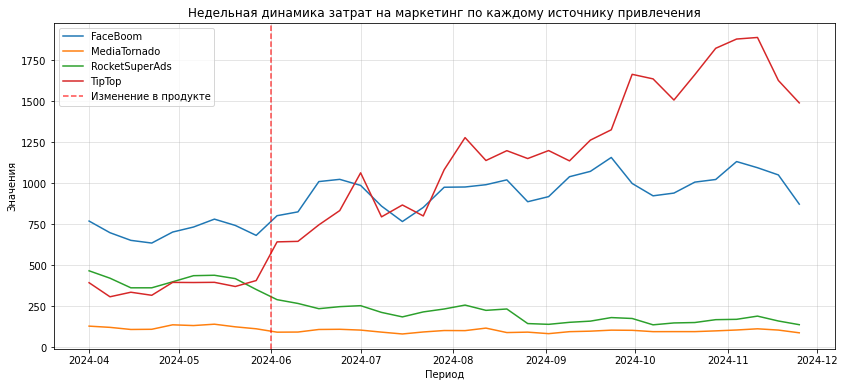

In [ ]:
# Создаем таблицу с маркетинговыми затратами для анализа по неделям
costs_weekly = df_costs

# Создаем столбец с неделей для группировки затрат
costs_weekly['week'] = costs_weekly['dt'].dt.to_period('W').dt.to_timestamp()


# Группируем затраты на маркетинг по неделям и каналам, суммируя расходы
costs_channel_weekly = costs_weekly.groupby(['week', 'channel'], as_index=False)['costs'].sum()

# Строим график в matplotlib
plt.subplots(figsize=(14,6))

# Строим графики для каждого канала
for channel in first_channel:
    df_plot = costs_channel_weekly[costs_channel_weekly['channel'] == channel]
    plt.plot(df_plot['week'], df_plot['costs'], label = channel)

# Покажем красной линией момент летнего изменеия в продукте
plt.axvline(x = pd.Timestamp('2024-06-01'), color='red', linestyle='--', alpha=0.7, label='Изменение в продукте')


# Оформляем график
plt.title('Недельная динамика затрат на маркетинг по каждому источнику привлечения')
plt.xlabel('Период')
plt.ylabel('Значения')
plt.legend()
plt.grid(alpha=0.4)
plt.show()



На графике видно, что маркетинговые затраты на каналы привлечения различаются. Больше всего затрат идет на канал TipTop, при этом затраты на него увеличиваются со временем. Второе место занимает FaceBoom c небольим положительным трендом. На третьем месте RocketSuperAds и затраты на него постеменно снижаются на протяжении всего периода. Стабильно мало затрат уходит на канал MediaTornado.

Можно заметить, что с лета изменилось распределение расходов на источники привлечения. На TipTop и FaceBoom тратить больше, на RocketSuperAds меньше. MediaTornado летние изменения никак не затронули.

Расчитаем и визуализируем САС.

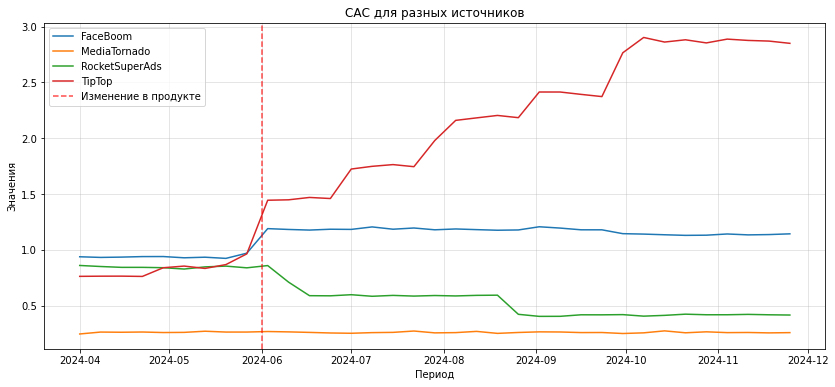

In [ ]:
# Объединим таблицы, созданные на предыдуших этапах:
# week_cohort_count - количество пользователей в недельных когортах
# costs_channel_weekly - недельные затраты на привлечние пользователей
cac_channel_weekly = pd.merge(
    week_cohort_count,
    costs_channel_weekly,
    left_on=['first_week', 'first_channel'],
    right_on=['week', 'channel'],
    how='left'
)

# Рассчитаем стоимость привлечения платящего пользователя по формуле: CAC = расходы на маркетинг / количество привлеченных пользователей
cac_channel_weekly['cac'] = cac_channel_weekly['costs'] / cac_channel_weekly['users_count']


# Строим график в matplotlib
plt.subplots(figsize=(14,6))

# Строим графики для каждого канала
for channel in first_channel:
    df_plot = cac_channel_weekly[cac_channel_weekly['first_channel'] == channel]
    plt.plot(df_plot['first_week'], df_plot['cac'], label = channel)

# Покажем красной линией момент летнего изменеия в продукте
plt.axvline(x = pd.Timestamp('2024-06-01'), color='red', linestyle='--', alpha=0.7, label='Изменение в продукте')


# Оформляем график
plt.title('САС для разных источников')
plt.xlabel('Период')
plt.ylabel('Значения')
plt.legend()

plt.grid(alpha=0.4)
plt.show()



Динамика САС похожа на график с абсолютными затратами на источники привлечения. Но здесь отчетливы видны изменения после июня.
Перейдем к расчёту LTV в разрезе каналов привлечения.

In [ ]:
# Считаем недельную выручку по когортам и сохраняем в новую таблицу ltv_weekly для расчета LTV
ltv_channel_weekly =  orders_count_period_28.groupby(
                    ['first_channel', 'first_week'], as_index=False)['revenue'].sum()

# Присоединяем к ltv_weekly таблицу week_cohort_count, где хранится информация о количестве привлеченных пользователей понедельно
ltv_channel_weekly = pd.merge(ltv_channel_weekly, week_cohort_count, on=['first_week', 'first_channel'], how='left')

# Считаем LTV: выручка за период / число пришедших пользователей за период
ltv_channel_weekly['ltv'] = ltv_channel_weekly['revenue'] / ltv_channel_weekly['users_count']

# Объединим таблицы ltv_weekly и cac_channel_weekly (хранит недельные САС)
cac_ltv_weekly = pd.merge(ltv_channel_weekly[['first_channel', 'first_week', 'ltv']],
                          cac_channel_weekly[['first_channel', 'first_week', 'cac']],
                          on=['first_week', 'first_channel'],
                          how='left')

#Выводим таблицу
show_df(cac_ltv_weekly)


,first_channel,first_week,ltv,cac
0,FaceBoom,2024-04-01,0.463854,0.938873
1,FaceBoom,2024-04-08,0.450013,0.933074
2,FaceBoom,2024-04-15,0.538608,0.935784
3,FaceBoom,2024-04-22,0.463151,0.940509
4,FaceBoom,2024-04-29,0.408300,0.940875


<class 'pandas.core.frame.DataFrame'>
Int64Index: 140 entries, 0 to 139
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   first_channel  140 non-null    object        
 1   first_week     140 non-null    datetime64[ns]
 2   ltv            140 non-null    float64       
 3   cac            140 non-null    float64       
dtypes: datetime64[ns](1), float64(2), object(1)
memory usage: 5.5+ KB



Визуализируем LTV и CAC по источникам. Построим графики для каждого канала отдельно.

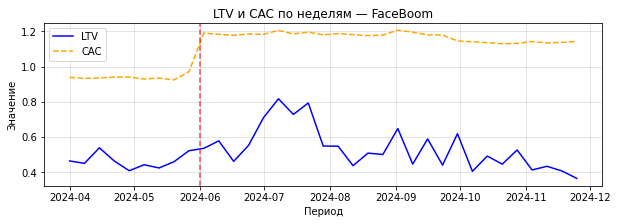

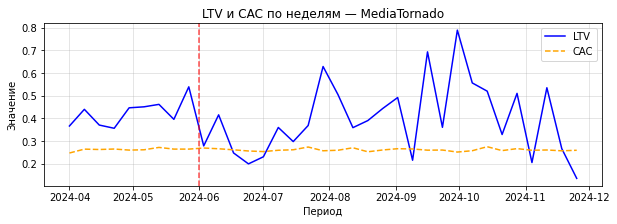

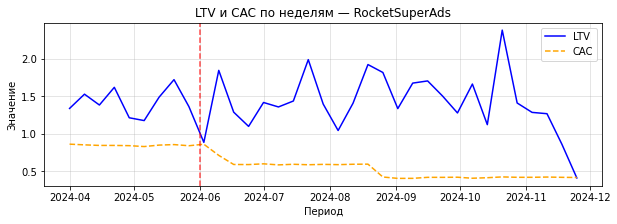

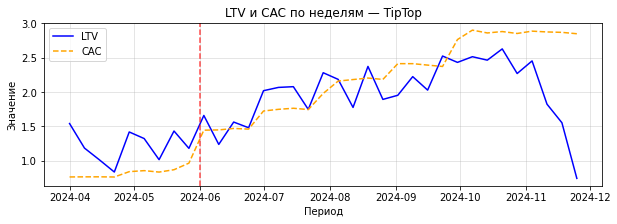

In [ ]:
# Устанавливаем размер графика
plt.rcParams['figure.figsize'] = (10, 3)

# Строим графики для каждого из четырёх источников
for channel in first_channel:
    # Фильтруем данные по источнику
    df_plot = (cac_ltv_weekly[cac_ltv_weekly['first_channel'] == channel].sort_values('first_week'))
    plt.figure()

    # Строим линию LTV
    plt.plot(df_plot['first_week'], df_plot['ltv'], color='blue', label='LTV')
    # Строим линию СAC
    plt.plot(df_plot['first_week'], df_plot['cac'], color='orange', linestyle='--', label='CAC')

    # Покажем летнее изменеие в продукте (июнь 2024)
    plt.axvline(x = pd.Timestamp('2024-06-01'), color='red', linestyle='--', alpha=0.7)

    # Оформляем график
    plt.title(f'LTV и CAC по неделям — {channel}')
    plt.xlabel('Период')
    plt.ylabel('Значение')
    plt.legend()
    plt.grid(alpha=0.4)
    plt.show()

Каналы существенно различаются по LTV и CAC, и их соотношению. Для ноябрьских когорт еще не наступил 28-дневный период по LTV, поэтому проанализируем динамику с апреля по октябрь включительно.

Для **FaceBoom** CAC стабильно выше LTV на всём периоде. После июня наблюдается рост CAC (около 1.15–1.20) без сопоставимого роста LTV.

**MediaTornado** показал низкий и стабильный CAC (около 0.25–0.27). LTV в большинстве недель превышает CAC, но график демонстирует сильную флуктуацию: есть отдельные пики LTV, однако устойчивого тренда роста  нет.

У канала **RocketSuperAds** лучшее соотношение LTV и CAC среди всех каналов. CAC снижается со временем (примерно с 0.85 до 0.42), при этом LTV остаётся высоким (больше 1.5).

У канала **TipTop** самые высокие значения и LTV, и CAC. Вслед за ростом CAC до 2.8–2.9, LTV тоже сопоставимо растёт в большинстве недель. Однако только в некоторые недели значение  LTV первышает CAC.



Рассчитаем и визуализируем ROI в разрезе каналов.

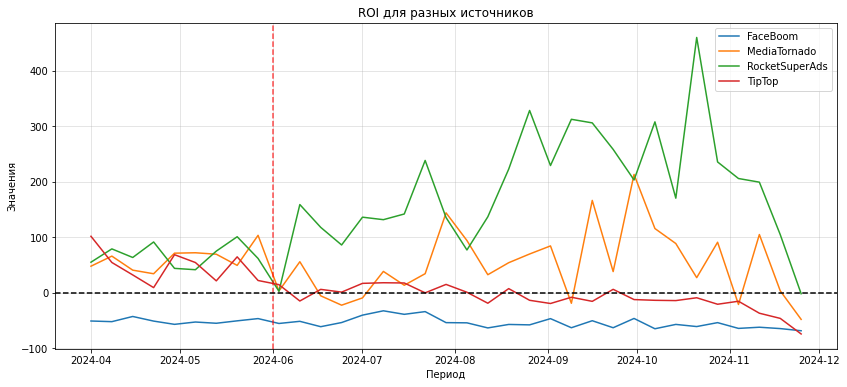

In [ ]:
# Рассчитаем ROI и сохраним итоговую таблицу в переменную с названием cac_ltv_roi_weekly
cac_ltv_weekly['roi'] = (cac_ltv_weekly['ltv'] - cac_ltv_weekly['cac']) / cac_ltv_weekly['cac'] * 100

# Создадим таблицу с подходящим названием для хранимых данных
cac_ltv_roi_weekly = cac_ltv_weekly

# Строим график в matplotlib
plt.subplots(figsize=(14,6))

# Строим графики для каждого канала
for channel in first_channel:
    df_plot = cac_ltv_roi_weekly[cac_ltv_roi_weekly['first_channel'] == channel]
    plt.plot(df_plot['first_week'], df_plot['roi'], label = channel)

# Покажем красной линией момент летнего изменеия в продукте
plt.axvline(x = pd.Timestamp('2024-06-01'), color='red', linestyle='--', alpha=0.7)

# Добавляем горизонтальную линию — границу окупаемости
plt.axhline(y=0, color='black', linestyle='--')

# Оформляем график
plt.title('ROI для разных источников')
plt.xlabel('Период')
plt.ylabel('Значения')
plt.legend()
plt.grid(alpha=0.4)
plt.show()




Опять же будем анализировать данные по ноябрь.

График ROI в разрезе каналов еще раз наглядно демонстрируют динамику, описанную выше при сравнении LTV и СAC.
Изменения в продукте и маркетинге в июне стали сказались для ROI, но эффект сильно различается по каналам.

У **FaceBoom** ROI остается отрицательным на всем периоде. До июня значения находились в диапазоне –45 - –55%, после июня — в основном –50 - –65%, с кратким улучшением в июле (до –32%). Изменения в продукте не коснулись экономики канала.

До июня **MediaTornado** показывал стабильный положительный ROI (40-100%). В июне–июле наблюдается снижение  до –22%, после чего канал демонстрирует рост ROI (140-210%), но с сильными колебания.

У **RocketSuperAds** наиболее выраженный положительный эффект от изменений. Если до июня ROI составлял 40-100%, то после июня он резко вырос: стабильно больше 130%, с пиками до 300–460% в сентябре–октябре. Канал стал лидером с точки зрения окупаемости.

До июня ROI у **TipTop** был положительным (20%-100%), но после изменений стал снизажться. Во второй половине периода ROI чаще находится в отрицательной зоне (–10 - -20%), что указывает на снижение эффективности канала при текущем уровне затрат и получаемой выручки.




**Промежуточный вывод**

Анализ выявил различия в эффективности рекламных каналов.

**TipTop** после июньских изменений стал ключевым каналом с точки зрения продуктовых метрик: рост DAU, MAU, удержания и вовлеченности подтверждает высокое качество аудитории. На канал была сделана ставка, если судить по росту маркетинговых затрат. Но увеличение стоимости привлечения (CAC) не сопровождаются сопоставимым ростом LTV. Если до лета канал окупался, то в летний и осенний периоды ROI часто остаётся ниже нулевого уровня.

**RocketSuperAds** показал наилучший финансовый результат: после июня канал сочетает высокий LTV со снижающимся CAC, обеспечивая устойчиво высокий ROI (с пиками до 300–460%), что делает его наиболее эффективным с точки зрения окупаемости.

**MediaTornado** привлекает небольшую, но относительно стабильную аудиторию с низким CAC и умеренными показателями LTV. Канал демонстрирует положительный ROI в отдельные периоды, но без устойчивого тренда роста.  

**FaceBoom** остаётся основным источником трафика (более 1/3 пользователей), однако привлекает слабо вовлеченную аудиторию: низкие показатели удержания (быстрый отток) и прилипания к продукту, вместе с невысокой выручкой и высокими затратами (САС), приводят к стабильно отрицательному ROI на всем периоде.



## Анализ периода окупаемости маркетинговых вложений

В этом разделе: <br>

Для источников, которые к 28-му дню не выходят на уровень окупаемости, рассчитаем и визуализируем в виде тепловой карты значения ROI за больший период, например за 8–10 недель. Разделим данные на недельные когорты по дате привлечения, в качестве интервала наблюдений будем использовать недели.

Сделаем вывод о том, за какой период окупаются вложения в эти источники.

<p style="font-size:20px"><strong>Недельный ROI по каналам FaceBoom и TipTop</strong></p>


Подготовим данные чтобы рассчитать недельный ROI.

In [ ]:
# Создадим таблицу, чтобы расчитать выручку для недельных когорт по неделям
week_orders = df_orders[['user_id', 'event_dt', 'first_dt', 'revenue', 'first_channel', 'first_week']]

# Создадим столбец с неделей покупки: для этого преобразуем дату покупки в неделю покупки
week_orders['week'] = week_orders['event_dt'].dt.to_period('W').dt.to_timestamp()

# Рассчитаем количество недель между неделей покупки и неделей привлечения
week_orders['week_period'] = week_orders['week'].dt.week - week_orders['first_week'].dt.week

# Посчитаем кумулятивную выручку для когорт (недель) по источникам и за недельный период
week_orders_grouped = week_orders.groupby(['first_channel','first_week', 'week_period'], as_index=False)['revenue'].sum()

#Выведем результат
display(week_orders_grouped.head(10))

,first_channel,first_week,week_period,revenue
0,FaceBoom,2024-04-01,0,290.63
1,FaceBoom,2024-04-01,1,62.81
2,FaceBoom,2024-04-01,2,20.94
3,FaceBoom,2024-04-01,3,5.98
4,FaceBoom,2024-04-01,6,2.99
5,FaceBoom,2024-04-01,11,4.49
6,FaceBoom,2024-04-01,15,2.99
7,FaceBoom,2024-04-01,20,2.99
8,FaceBoom,2024-04-08,0,280.20
9,FaceBoom,2024-04-08,1,32.93


Далее добавим в полученную таблицу расчитанный недельный CAC, количество привлеченных пользователей, после рассчитаем LTV и ROI.

In [ ]:
# Добавляем в таблицу данные о недельном CAC
week_metrics_cac_ltv_roi = pd.merge(week_orders_grouped[
    ['first_week', 'first_channel', 'week_period', 'revenue']],
    cac_channel_weekly[['first_week', 'first_channel', 'cac']],
    on=['first_week', 'first_channel'], how='left')

# Добавляем информацию о количестве привлеченных пользователей для расчета LTV
week_metrics_cac_ltv_roi = pd.merge(week_metrics_cac_ltv_roi, ltv_channel_weekly[
    ['first_week', 'first_channel', 'users_count']], on=['first_week', 'first_channel'], how='left')

# Рассчитаем кумулятивную сумму выручки по каналу и периоду
week_metrics_cac_ltv_roi['cumsum_revenue'] = week_metrics_cac_ltv_roi.groupby(
    ['first_week', 'first_channel'])['revenue'].cumsum()

# Считаем LTV
week_metrics_cac_ltv_roi['ltv'] = week_metrics_cac_ltv_roi['cumsum_revenue'] / week_metrics_cac_ltv_roi['users_count']

# Рассчитаем ROI
week_metrics_cac_ltv_roi['roi'] = (week_metrics_cac_ltv_roi['ltv'] - week_metrics_cac_ltv_roi['cac']) / week_metrics_cac_ltv_roi['cac']

# Создадим таблицу со стобцами, необходимыми для дальнейшей визуализации
week_roi = week_metrics_cac_ltv_roi[['first_week', 'first_channel', 'week_period', 'roi']]

# Выведем результат
display(week_roi.head())

,first_week,first_channel,week_period,roi
0,2024-04-01,FaceBoom,0,-0.622498
1,2024-04-01,FaceBoom,1,-0.540913
2,2024-04-01,FaceBoom,2,-0.513714
3,2024-04-01,FaceBoom,3,-0.505946
4,2024-04-01,FaceBoom,6,-0.502063


Визуализируем ROI по всем когортам, используя тепловую карту. Проверим, окупаются ли каналы FaceBoom и TipTop за 10 недель.

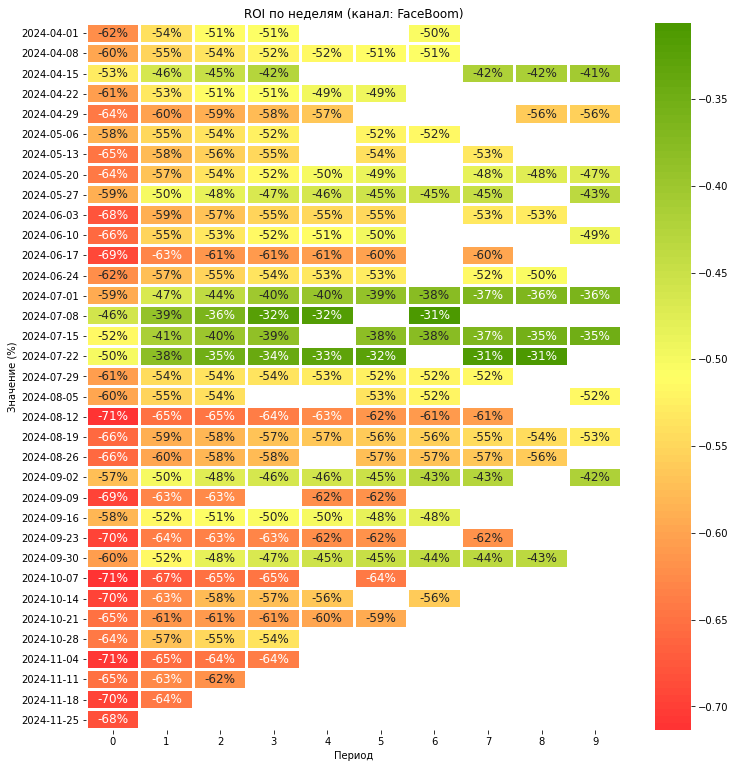

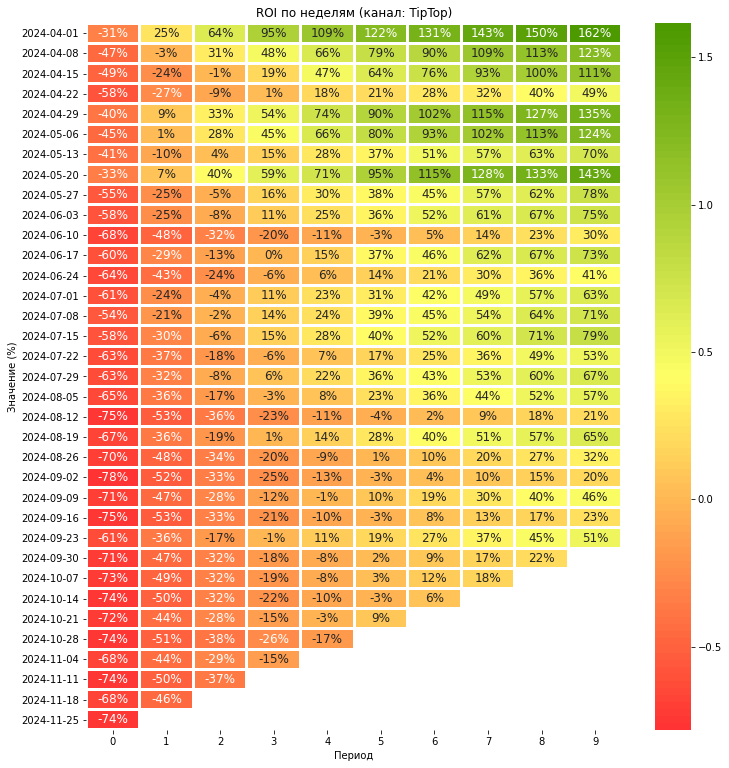

In [ ]:
# Отфильтуем период до 10 недель
week_roi_10 = week_roi[week_roi['week_period'].between(0,9)]

# Создаем пользовательскую цветовую карту для визуализации значений ROI
cmap = mcolors.LinearSegmentedColormap.from_list('green_red', ['#FF3333', '#FFFF66', '#4C9900'], N=100)

selected_channels = ['FaceBoom', 'TipTop']

# Устанавливаем размер графика
plt.rcParams['figure.figsize'] = (12, 13)

# Создаем цикл, который будет фильтровать таблицу по источникам, пивотировать данные и создавать тепловую карту
for channel in selected_channels:
    df_filtered = week_roi_10[week_roi_10['first_channel'] == channel]
    pivot_roi = df_filtered.pivot(index = 'first_week', columns = 'week_period', values = 'roi')

    # Приводим first_week в подходящий вид для отображения
    pivot_roi.index = pd.to_datetime(pivot_roi.index).strftime('%Y-%m-%d')

    # Строим тепловую карту
    sns.heatmap(pivot_roi,
          cmap=cmap,
          annot=True,
          fmt='.0%',
          linewidths=2,
          annot_kws={"size": 12},
          )

    # Добавим название и подписи
    plt.title(f'ROI по неделям (канал: {channel})')
    plt.xlabel('Период')
    plt.ylabel('Значение (%)')
    plt.show()


**FaceBoom** демонстрирует устойчиво отрицательный ROI на всех когортах и недельных перодах (10 недель). Несмотря на спорадические улучшения показателя, канал не достигает уровня окупаемости за 10 дней. Это означает, что вложения в канал не окупаются в этом временном горизонте и есть сомнения, что они буду окупяться вообще, учитывая низкие значения удержания и активности у пользователей этого канала.

У **TipTop** заметно ухудшается метрика ROI по когортам и срок окупаемости увеличивается: в весенних когортах выход в положительный ROI происходит в среднем на 2–4 неделе, на 4-5 неделе, а вот в сентябре-октябре на 5-6 неделе. Начиная с июня срок окупаемости увеличивается — положительный ROI достигается позже (5–7 неделя). Это говорит о снижение эффективности (отдачи) при росте затрат.

Можно заключить, что FaceBoom — канал без окупаемости, а TipTop остается окупаемым, но после июня возврат инвестиций замедлился, что требует контроля затрат, пересмотра масштабирования.

## Выводы и рекомендации



Аудитория продукта неоднородна по источникам привлечения. Каналы различаются по объёму трафика, качеству пользователей, их вовлечённости (активности), удержанию и экономическим показателям.

Маркетинговые затраты сосредоточены в двух каналах - TipTop и FaceBoom. При этом эффективность вложений между ними принципиально различается.

**FaceBoom** является основным источником привлечения аудитории по объёму. Пользователи быстро совершают покупку, однако плохо удерживаются в продукте. LTV стабильно ниже CAC, ROI остается отрицательным на всем горизонте анализа. Канал не окупается.

**TipTop** привлекает наиболее активную и вовлеченную аудиторию: высокие DAU, MAU, удержание и stickiness. Однако есть следующая проблема: до летних изменений канал окупался быстро, но после роста маркетинговых затрат срок окупаемости увеличился. Канал остается стратегически важным, но требует оптимизации расходов.

**RocketSuperAds** - самый эффективный канал с точки зрения юнит-экономики. При умеренном объеме привлекаемой аудитории канал демонстрирует высокое LTV, снижающийся CAC и, как разультат, стабильно положительный ROI.

**MediaTornado** привлекает небольшую, но относительно лояльную аудиторию со среднем показателем удержания (еще один минус - самая низкая конверсия в покупку). Экономика канала нестабильна - при самом низком показателе CAC LTV сильно колеблется. Это ограничивает масштабирование.

Можно заключить, что выручка начала стагнировать после летних изменений из-за смещения фокуса маркетинга в сторону каналов с более высокой вовлечённостью, но худшей экономикой в краткосрочном периоде. Основной рост пришелся на TipTop, который привлекает активную аудиторию, однако рост CAC опережал рост LTV, а срок окупаемости увеличился. Одновременно сократился вклад в канал с более стабильной и быстрой монетизацией (RocketSuperAds). Всё это в совокупности привело к замедлению прироста выручки, несмотря на рост DAU и MAU.
(*Канал FaceBoom в данном контексте можно рассматривать отдельно: он не выходил на окупаемость ни до, ни после изменений и является системной проблемой.*)


**Рекомендации маркетингу: перераспределение затрат по каналам привлечения**

- Стоит сократить или пересмотреть канал привлечения FaceBoom из-за отсутствия окупаемости.

- Оптимизировать TipTop: рост затрат не приводит к пропорциональному росту LTV, поэтому стоит контролировать рост CAC и искать точки повышения LTV.

- Стоит увеличить инвестиции в RocketSuperAds — канал демонстрирует лучшую окупаемость.

- Использовать MediaTornado с осторожностью: можно умеренно увеличить инветсиции, учитывая, что показатели удержания и вовлечения у канала достаточно хорошие.

Общая рекомендация: регулярно отслеживать ROI по когортам и каналам, особенно после изменений в продукте и маркетинговой стратегии.